# Figure generation - MBE revision

Run top to bottom. Writes vector PDF and 600 dpi PNG beside this notebook,
one pair per figure. Figure 4 and Figure S3 read `../data/BCAT1_KO Fed-Batch.xlsx`.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt

OUT = Path.cwd()          # write beside this notebook

def save(fig, name):
    fig.savefig(OUT / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(OUT / f'{name}.png', dpi=600, bbox_inches='tight')
    print('wrote', name)


C:\Users\Arago\AppData\Local\Temp\ipykernel_32772\2281144955.py:193: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


wrote Fig1_computational_optimisation
Done


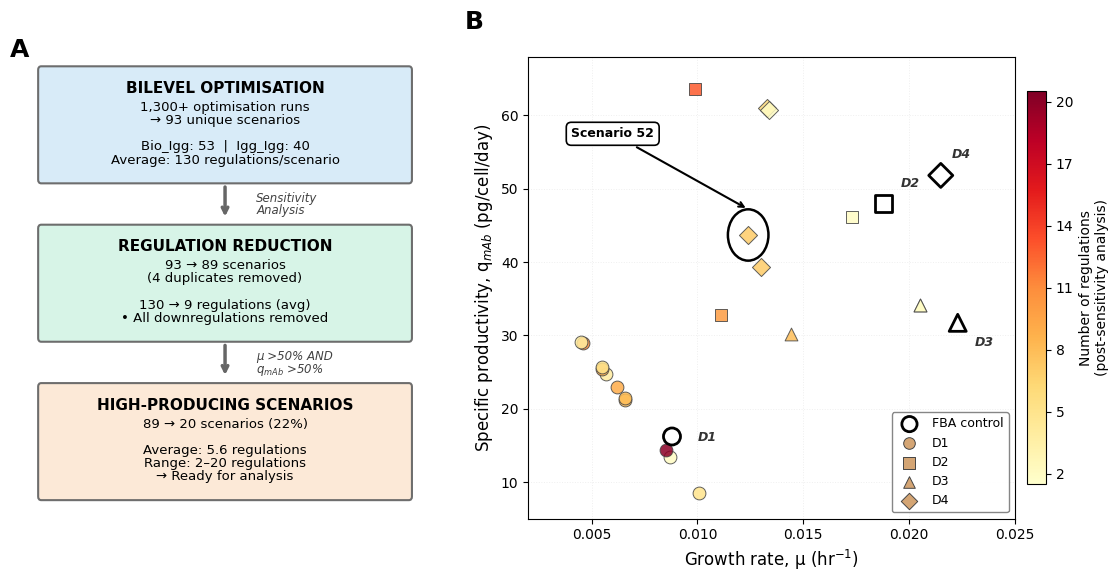

In [2]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
from matplotlib.patches import FancyBboxPatch

# === DATA ===
scenarios = [
    # D1 scenarios
    (1, 'D1', 'Bio_Igg', 0.0066, 21.2311, 8),
    (3, 'D1', 'Bio_Igg', 0.0057, 24.7229, 4),
    (9, 'D1', 'Igg_Igg', 0.0046, 28.9245, 11),
    (12, 'D1', 'Igg_Igg', 0.0101, 8.4772, 5),
    (27, 'D1', 'Igg_Igg', 0.0055, 25.4711, 9),
    (47, 'D1', 'Igg_Igg', 0.0087, 13.4181, 2),
    (80, 'D1', 'Bio_Igg', 0.0045, 29.0373, 4),
    (81, 'D1', 'Bio_Igg', 0.0062, 22.9280, 9),
    (84, 'D1', 'Bio_Igg', 0.0066, 21.4020, 8),
    (86, 'D1', 'Bio_Igg', 0.0055, 25.6321, 5),
    (88, 'D1', 'Bio_Igg', 0.0085, 14.3019, 20),
    # D2 scenarios
    (30, 'D2', 'Igg_Igg', 0.0099, 63.6437, 13),
    (31, 'D2', 'Igg_Igg', 0.0173, 46.0704, 2),
    (74, 'D2', 'Igg_Igg', 0.0111, 32.7011, 10),
    # D3 scenarios
    (32, 'D3', 'Bio_Igg', 0.0205, 34.0823, 2),
    (33, 'D3', 'Bio_Igg', 0.0205, 34.0823, 2),
    (47, 'D3', 'Igg_Igg', 0.0144, 30.115, 8),
    # D4 scenarios
    (14, 'D4', 'Bio_Igg', 0.0133, 61.0383, 6),
    (49, 'D4', 'Bio_Igg', 0.0130, 39.3633, 7),
    (52, 'D4', 'Bio_Igg', 0.0124, 43.6783, 7),
    (58, 'D4', 'Bio_Igg', 0.0134, 60.7551, 2),
]

controls = {
    'D1': (0.0088, 16.2),
    'D2': (0.0188, 48.0),
    'D3': (0.0223, 31.7),
    'D4': (0.0215, 51.8),
}

ds_markers = {'D1': 'o', 'D2': 's', 'D3': '^', 'D4': 'D'}

# Colour map
all_regs = [s[5] for s in scenarios]
cmap = cm.YlOrRd
norm = mcolors.Normalize(vmin=min(all_regs) - 0.5, vmax=max(all_regs) + 0.5)

# === FIGURE ===
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(1, 2, width_ratios=[0.40, 0.60], wspace=0.22)

# --- PANEL A: FLOWCHART ---
ax_flow = fig.add_subplot(gs[0])
ax_flow.set_xlim(0, 10)
ax_flow.set_ylim(-0.5, 10)
ax_flow.axis('off')

def add_box(ax, x, y, width, height, title, lines, color):
    box = FancyBboxPatch((x, y), width, height,
                          boxstyle="round,pad=0.08",
                          facecolor=color,
                          edgecolor='#666666',
                          linewidth=1.5,
                          alpha=0.95)
    ax.add_patch(box)
    ax.text(x + width/2, y + height - 0.25, title,
            ha='center', va='top', fontsize=11, fontweight='bold')
    y_text = y + height - 0.7
    for line in lines:
        ax.text(x + width/2, y_text, line,
                ha='center', va='top', fontsize=9.5)
        y_text -= 0.3

def add_arrow(ax, x1, y1, x2, y2, label=''):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', lw=2.5, color='#666666'))
    if label:
        label_lines = label.split('\n')
        y_offset = (y1 + y2)/2
        for i, line in enumerate(label_lines):
            ax.text(5.8, y_offset - i*0.28, line,
                    fontsize=8.5, ha='left', style='italic', color='#424242')

add_box(ax_flow, 0.3, 7.2, 9.4, 2.5,
        'BILEVEL OPTIMISATION',
        ['1,300+ optimisation runs',
         '\u2192 93 unique scenarios',
         '',
         'Bio_Igg: 53  |  Igg_Igg: 40',
         'Average: 130 regulations/scenario'],
        '#D6EAF8')

add_arrow(ax_flow, 5, 7.1, 5, 6.3, 'Sensitivity\nAnalysis')

add_box(ax_flow, 0.3, 3.6, 9.4, 2.5,
        'REGULATION REDUCTION',
        ['93 \u2192 89 scenarios',
         '(4 duplicates removed)',
         '',
         '130 \u2192 9 regulations (avg)',
         '\u2022 All downregulations removed'],
        '#D5F4E6')

add_arrow(ax_flow, 5, 3.5, 5, 2.7, '\u03bc >50% AND\nq$_{mAb}$ >50%')

add_box(ax_flow, 0.3, 0.0, 9.4, 2.5,
        'HIGH-PRODUCING SCENARIOS',
        ['89 \u2192 20 scenarios (22%)',
         '',
         'Average: 5.6 regulations',
         'Range: 2\u201320 regulations',
         '\u2192 Ready for analysis'],
        '#FCE8D5')

ax_flow.text(-0.5, 10, 'A', fontsize=18, fontweight='bold')

# --- PANEL B: SCATTER PLOT ---
ax = fig.add_subplot(gs[1])

# Plot control points (hollow)
for ds, (mu, qmab) in controls.items():
    ax.scatter(mu, qmab, marker=ds_markers[ds], s=150,
              facecolors='none', edgecolors='black', linewidths=2.0, zorder=4)

# Label controls
ctrl_offsets = {
    'D1': (0.0012, -1.0),
    'D2': (0.0008, 1.8),
    'D3': (0.0008, -3.5),
    'D4': (0.0005, 2.0),
}
for ds, (mu, qmab) in controls.items():
    dx, dy = ctrl_offsets[ds]
    ax.text(mu + dx, qmab + dy, ds, fontsize=9, fontstyle='italic',
            fontweight='bold', color='#333333', ha='left', va='bottom')

# Plot all scenarios including 52 with normal markers
s52 = [s for s in scenarios if s[0] == 52][0]
for scen, ds, algo, mu, qmab, nregs in scenarios:
    colour = cmap(norm(nregs))
    ax.scatter(mu, qmab, marker=ds_markers[ds], s=85,
              c=[colour], edgecolors='#444444', linewidths=0.7,
              zorder=3, alpha=0.85)

# Circle highlight around Scenario 52
from matplotlib.patches import Ellipse
# Use ellipse to account for different axis scales
x_range = 0.025 - 0.002
y_range = 68 - 5
aspect = (x_range / y_range)  # ratio of axis ranges
circle_r_y = 3.5  # radius in y-data units
circle_r_x = circle_r_y * aspect * (6/8)  # adjust for figure aspect ratio
ellipse = Ellipse((s52[3], s52[4]), width=2*circle_r_x, height=2*circle_r_y,
                  fill=False, edgecolor='black', linewidth=1.8, linestyle='-', zorder=5)
ax.add_patch(ellipse)
ax.annotate('Scenario 52',
           xy=(s52[3], s52[4] + circle_r_y),
           xytext=(0.006, 57),
           bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                    edgecolor='black', linewidth=1.2),
           arrowprops=dict(arrowstyle='->', lw=1.5, color='black'),
           fontsize=9, fontweight='bold', ha='center', zorder=6)

# Legend
ax.scatter([], [], marker='o', s=120, facecolors='none', edgecolors='black',
          linewidths=2, label='FBA control')
for ds, marker in ds_markers.items():
    ax.scatter([], [], marker=marker, s=70, c='#D4A574', edgecolors='#444444',
              linewidths=0.7, label=ds)

ax.legend(loc='lower right', frameon=True, fancybox=True,
         fontsize=9, framealpha=0.95, edgecolor='gray')

# Colourbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02, shrink=0.85)
cbar.set_label('Number of regulations\n(post-sensitivity analysis)', fontsize=10)
cbar.set_ticks([2, 5, 8, 11, 14, 17, 20])

ax.set_xlabel('Growth rate, \u03bc (hr$^{-1}$)', fontsize=12)
ax.set_ylabel('Specific productivity, q$_{mAb}$ (pg/cell/day)', fontsize=12)

ax.grid(True, alpha=0.2, linestyle=':', linewidth=0.7)
ax.set_xlim(0.002, 0.025)
ax.set_ylim(5, 68)

ax.text(-0.13, 1.06, 'B', transform=ax.transAxes,
       fontsize=18, fontweight='bold')

plt.tight_layout()
save(plt.gcf(), 'Fig1_computational_optimisation')
print("Done")


viability: max |Results mean - FinalResults| per line, percentage points
   CHO      24.7
   CHO′     18.5
   CHO-B    19.4
wrote Fig4_fedbatch_performance
wrote FigS3_cumulative_leucine
final IVCD : {'CHO': np.float64(2038.0), 'CHO′': np.float64(2213.0), 'CHO-B': np.float64(1824.5)}
final titre: {'CHO': np.float64(1.844), 'CHO′': np.float64(1.783), 'CHO-B': np.float64(2.662)}
  CHO    cumulative leucine  0.3810 pmol/cell   titre/leucine  4.840
  CHO′   cumulative leucine  0.3667 pmol/cell   titre/leucine  4.863
  CHO-B  cumulative leucine  0.4014 pmol/cell   titre/leucine  6.631
written Fig4_fedbatch_performance and FigS3_cumulative_leucine (.pdf and .png)


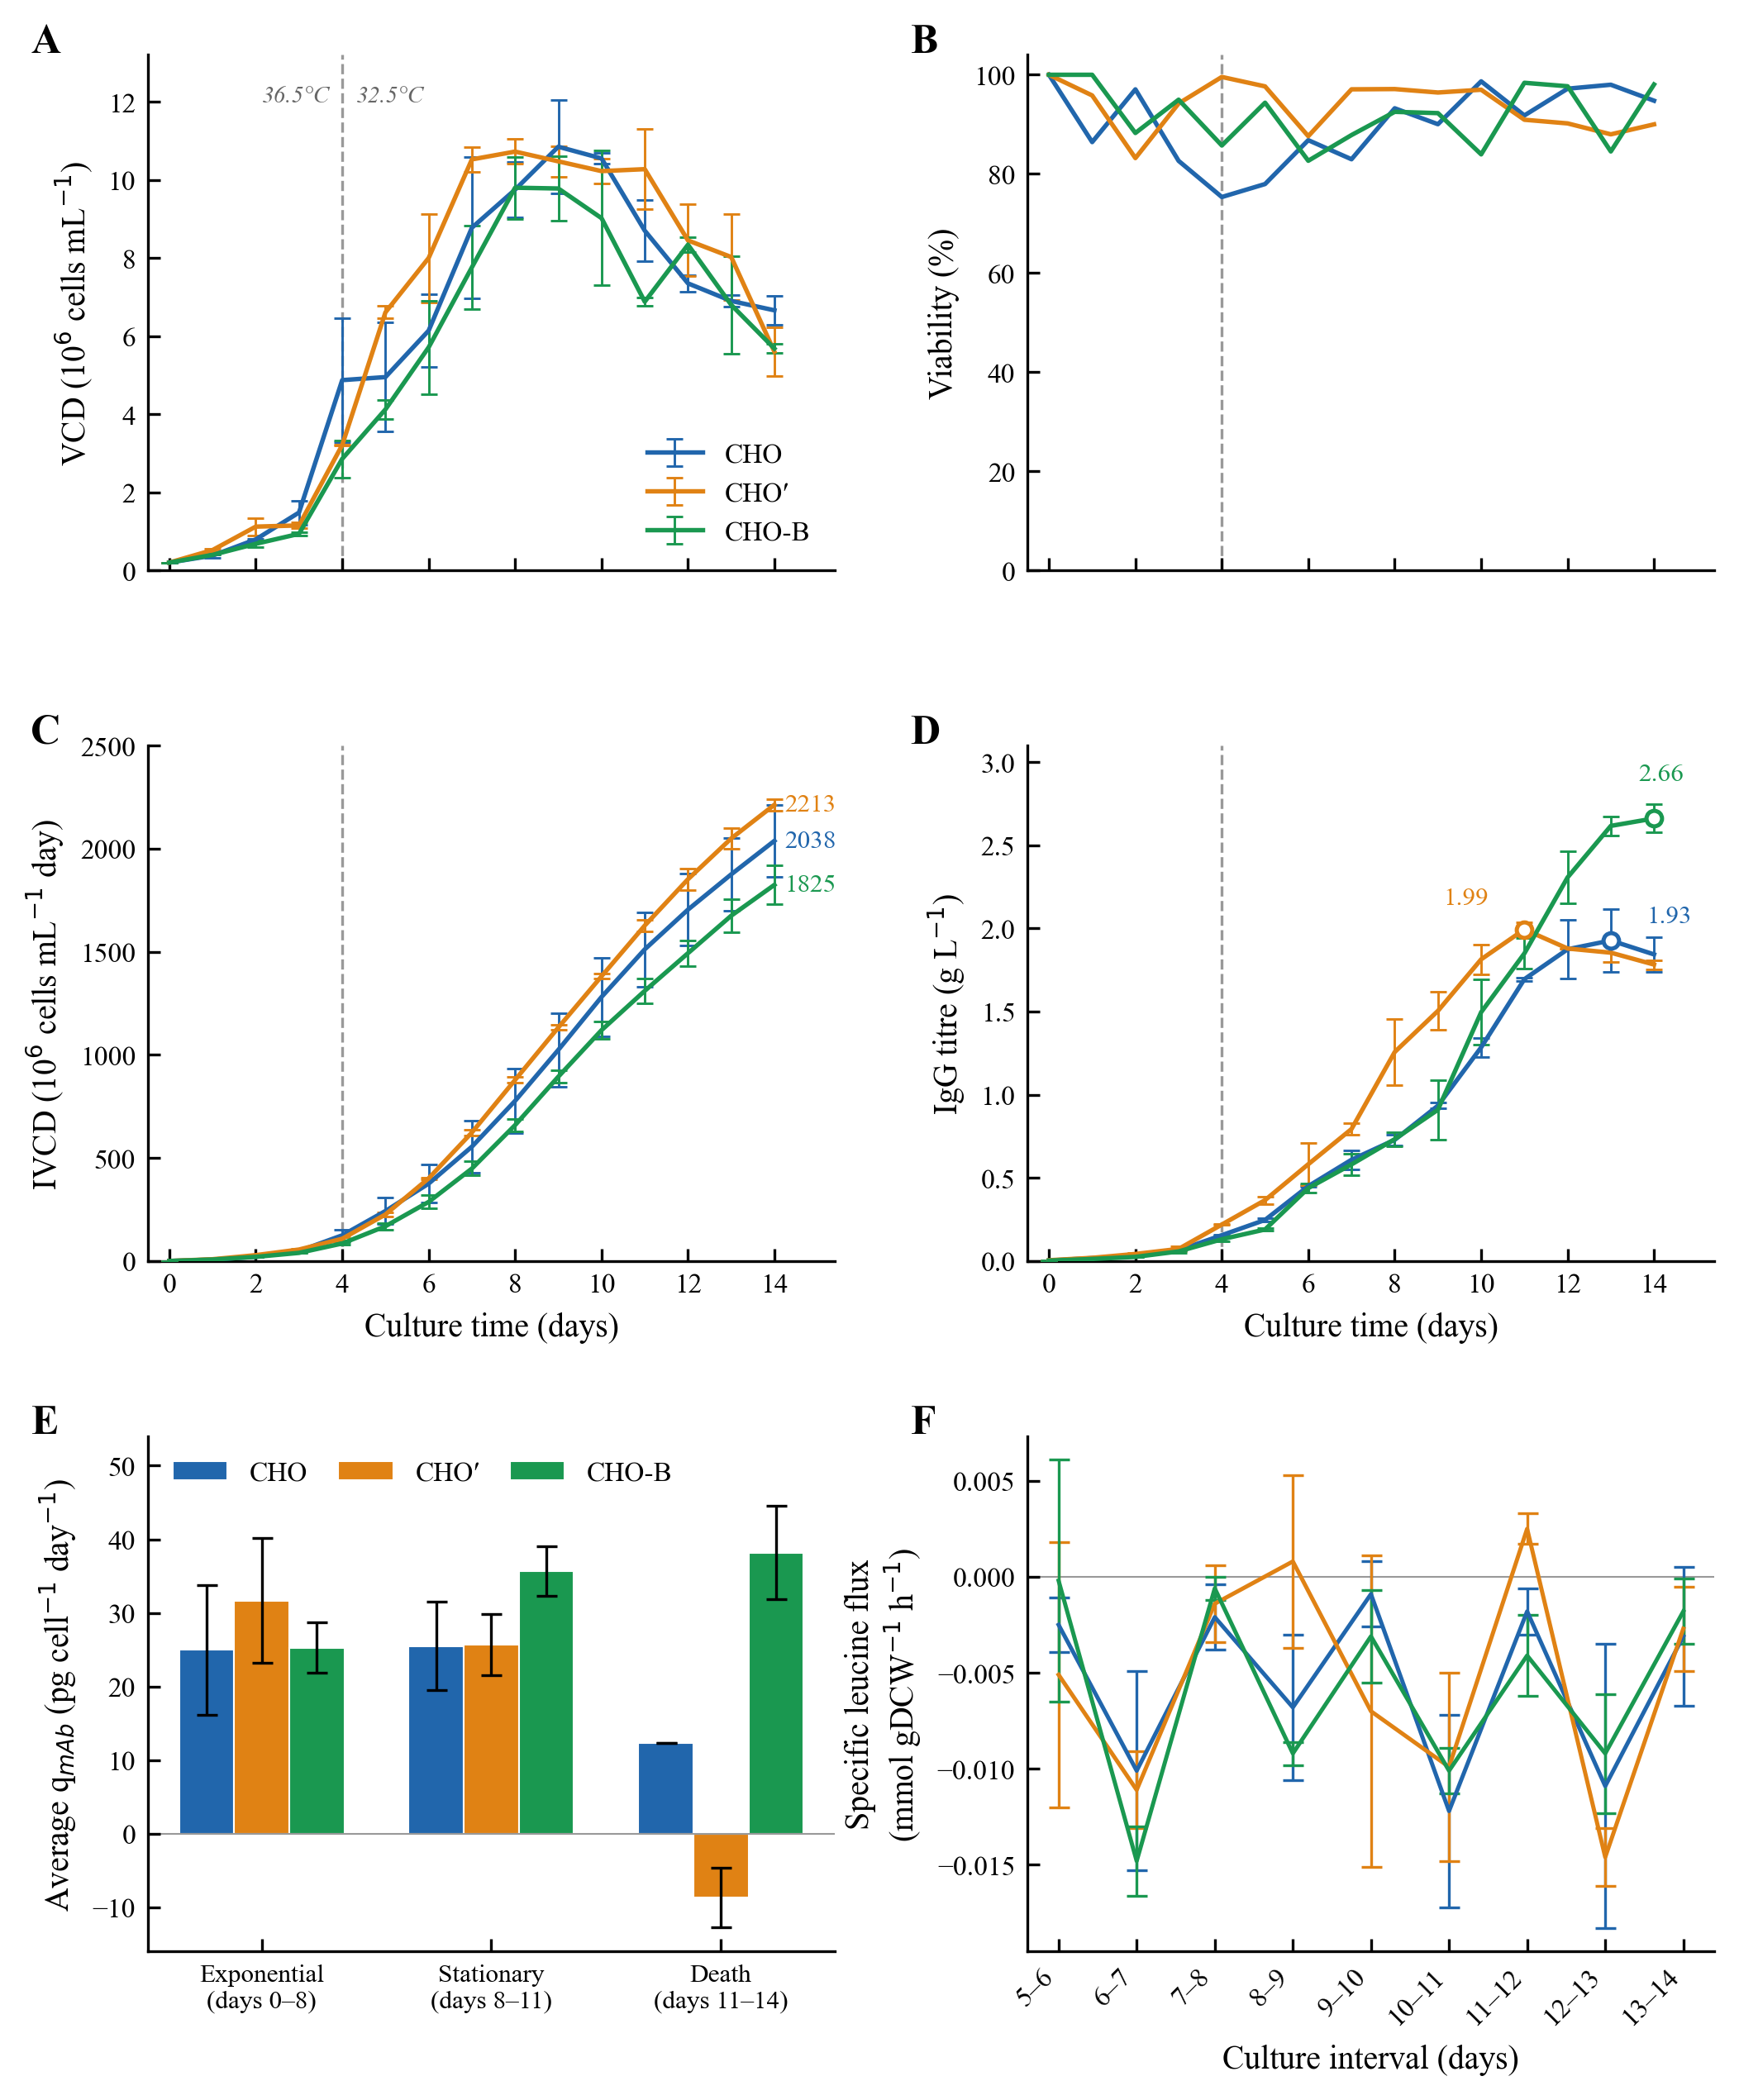

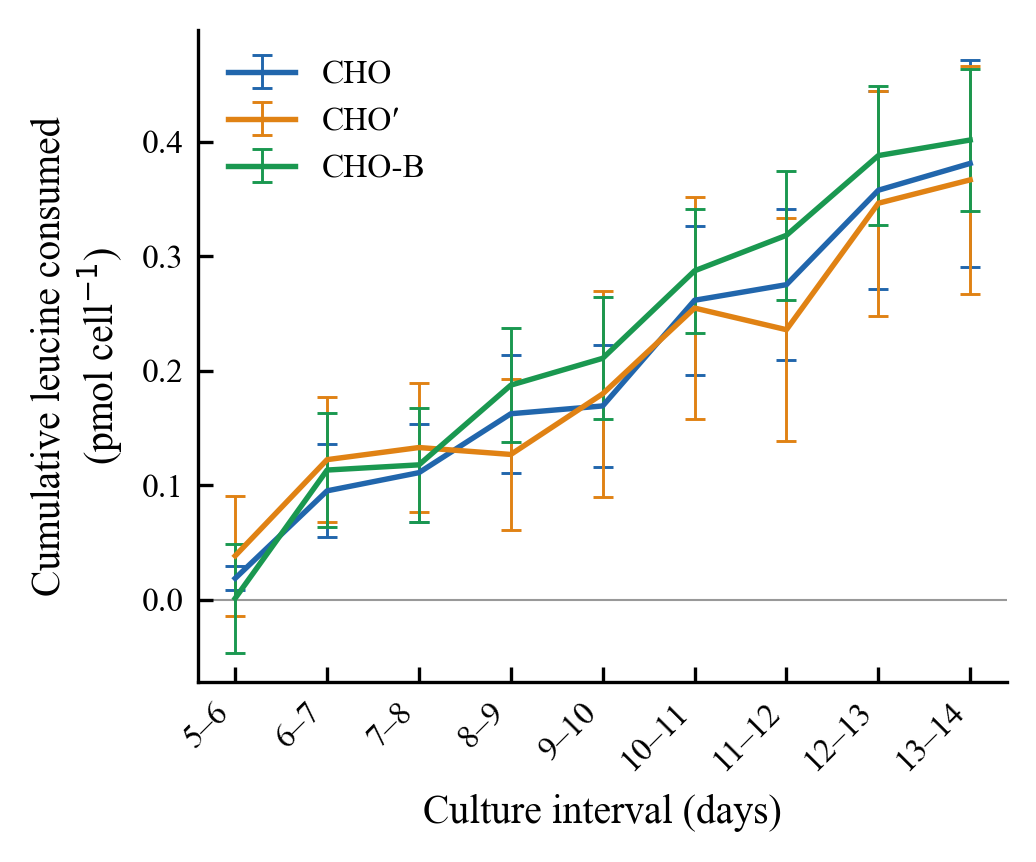

In [3]:
"""Figure 4 (rebuilt): integrated process performance, six panels, 3x2.

Consolidates panels currently spread across Figures 4-6 so a reader can tell
whether the titre gain came from more cells, a longer culture, or higher
per-cell productivity.

A VCD          B viability        (row 1)
C IVCD         D IgG titre        (row 2)
E qmAb by phase  F leucine flux   (row 3)

A/C and B/D share a daily x-axis and are aligned vertically. The day-4
temperature shift is marked on every time-course panel.

Time courses come from data/BCAT1_KO Fed-Batch.xlsx (FinalResults);
phase-averaged qmAb and the leucine flux trace come from Figures.ipynb.
"""

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import openpyxl

HERE = Path.cwd()
XLSX = HERE.parent / "data" / "BCAT1_KO Fed-Batch.xlsx"

C_CHO, C_CHOP, C_CHOB = "#2166AC", "#E08214", "#1A9850"
LINES = [("CHO", 15, C_CHO), ("CHO\u2032", 2, C_CHOP), ("CHO-B", 28, C_CHOB)]
SHIFT_DAY = 4

mpl.rcParams.update({
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 9, "axes.labelsize": 9.5, "xtick.labelsize": 8,
    "ytick.labelsize": 8, "legend.fontsize": 8, "legend.frameon": False,
    "figure.dpi": 300, "savefig.dpi": 300,
    "axes.linewidth": .8, "xtick.major.width": .8, "ytick.major.width": .8,
    "xtick.direction": "in", "ytick.direction": "in",
    "axes.spines.top": False, "axes.spines.right": False,
})

# --- time courses from the workbook -----------------------------------------
# column offsets from each cell line's block start, per the FinalResults header
DAY, VCD, VCD_SD, VIAB, IVCD, IVCD_SD, TITRE, TITRE_SD = 0, 2, 3, 4, 5, 6, 8, 9

ws = openpyxl.load_workbook(XLSX, data_only=True, read_only=True)["FinalResults"]
ROWS = [r for r in ws.iter_rows(min_row=4, max_row=18, values_only=True)]


def series(base, offset):
    out = []
    for row in ROWS:
        try:
            out.append(float(row[base + offset]))
        except (TypeError, ValueError):
            out.append(np.nan)
    return np.array(out)


# viability is only averaged in FinalResults; the two replicates live in
# `Results`, in three blocks stacked at rows 2 / 24 / 46 (rep 1 col 6, rep 2 col 17)
VIAB_BLOCK = {"CHO′": 5, "CHO": 27, "CHO-B": 49}
RES = openpyxl.load_workbook(XLSX, data_only=True, read_only=True)["Results"]
RES_ROWS = [r for r in RES.iter_rows(min_row=1, max_row=63, max_col=26,
                                     values_only=True)]


def viability_replicates(first_row):
    """Per-replicate viability recomputed from the primary counts, VCD/(VCD+DCD).

    The stored viability column is used only as a cross-check: it agrees
    everywhere except CHO' day 4 replicate 2, which records 0% alongside
    3.2e6 viable cells and is a transcription error.
    """
    reps = []
    for row in RES_ROWS[first_row - 1:first_row - 1 + 15]:
        pair = []
        for vcd_c, dcd_c in ((4, 5), (15, 16)):
            try:
                vcd, dcd = float(row[vcd_c]), float(row[dcd_c])
                pair.append(vcd / (vcd + dcd) if vcd + dcd > 0 else np.nan)
            except (TypeError, ValueError):
                pair.append(np.nan)
        reps.append(pair)
    arr = 100 * np.asarray(reps)
    return arr.mean(axis=1), arr.std(axis=1, ddof=1)


days = series(15, DAY)
data = {name: {k: series(base, off) for k, off in
               (("vcd", VCD), ("vcd_sd", VCD_SD), ("viab", VIAB),
                ("ivcd", IVCD), ("ivcd_sd", IVCD_SD),
                ("titre", TITRE), ("titre_sd", TITRE_SD))}
        for name, base, _ in LINES}

for name, _, _ in LINES:
    mean, sd = viability_replicates(VIAB_BLOCK[name])
    data[name]["viab_mean"], data[name]["viab_sd"] = mean, sd

# guard the block mapping against the values published in Figures.ipynb
assert np.allclose(data["CHO\u2032"]["vcd"][:4], [0.2, 0.52, 1.12, 1.15])
assert np.allclose(data["CHO"]["vcd"][:4], [0.2, 0.378, 0.793, 1.48])
assert np.allclose(data["CHO-B"]["titre"][-1], 2.662, atol=1e-3)
# UNRESOLVED: the two sheets carry different viability series. `Results` is
# internally consistent (its stored column equals VCD/(VCD+DCD) everywhere bar
# the one bad cell), but its replicate means do not reproduce the `FinalResults`
# viability. Panel B is drawn from `Results`; flip VIABILITY_SOURCE to compare.
VIABILITY_SOURCE = "FinalResults"        # or "FinalResults" (no error bars available)
print("viability: max |Results mean - FinalResults| per line, percentage points")
for name, _, _ in LINES:
    gap = np.nanmax(np.abs(data[name]["viab_mean"] - 100 * data[name]["viab"]))
    print(f"   {name:6s} {gap:6.1f}")

# --- phase-averaged qmAb and leucine flux, from Figures.ipynb ---------------
PHASES = ["Exponential\n(days 0\u20138)", "Stationary\n(days 8\u201311)",
          "Death\n(days 11\u201314)"]
PHASE_Q = {"CHO": ([25.0, 25.5, 12.3], [8.8, 6.0, 0.0]),
           "CHO\u2032": ([31.7, 25.7, -8.66], [8.5, 4.1, 4.05]),
           "CHO-B": ([25.3, 35.7, 38.2], [3.4, 3.4, 6.3])}

INTERVALS = ["5\u20136", "6\u20137", "7\u20138", "8\u20139", "9\u201310",
             "10\u201311", "11\u201312", "12\u201313", "13\u201314"]
FLUX = {
    "CHO": ([-.0025, -.0101, -.0021, -.0068, -.0009, -.0122, -.0018, -.0109, -.0031],
            [.0014, .0052, .0017, .0038, .0017, .0050, .0012, .0074, .0036]),
    "CHO\u2032": ([-.0051, -.0111, -.0014, .0008, -.0070, -.0099, .0025, -.0146, -.0027],
                  [.0069, .0020, .0020, .0045, .0081, .0049, .0008, .0015, .0022]),
    "CHO-B": ([-.0002, -.0148, -.0006, -.0092, -.0031, -.0101, -.0041, -.0092, -.0018],
              [.0063, .0018, .0006, .0006, .0024, .0012, .0021, .0031, .0017]),
}
CDW_NG, HOURS = 0.315, 24.0        # ng/cell; h/day -> pmol cell-1 day-1


def shift_marker(ax, label_y, first=False):
    ax.axvline(SHIFT_DAY, color="0.6", lw=.8, ls="--", zorder=1)
    if first:
        ax.annotate("36.5\u00b0C", xy=(SHIFT_DAY - 0.3, label_y), fontsize=7,
                    color="0.4", style="italic", ha="right")
        ax.annotate("32.5\u00b0C", xy=(SHIFT_DAY + 0.3, label_y), fontsize=7,
                    color="0.4", style="italic", ha="left")


def panel_letter(ax, letter):
    ax.text(-0.17, 1.06, letter, transform=ax.transAxes, fontsize=12,
            fontweight="bold", va="top")


def errline(ax, x, y, e, colour, label):
    ax.errorbar(x, y, yerr=e, color=colour, lw=1.3, capsize=2.5,
                capthick=.7, elinewidth=.7, label=label, zorder=3)


fig, axes = plt.subplots(3, 2, figsize=(7.1, 8.5))
fig.subplots_adjust(left=.095, right=.985, top=.965, bottom=.065,
                    hspace=.34, wspace=.28)
(axA, axB), (axC, axD), (axE, axF) = axes

# A -- VCD
for name, _, colour in LINES:
    errline(axA, days, data[name]["vcd"], data[name]["vcd_sd"], colour, name)
shift_marker(axA, 12.0, first=True)
axA.set_ylabel("VCD (10$^6$ cells mL$^{-1}$)")
axA.set_ylim(0, 13.2); axA.legend(loc="lower right")
panel_letter(axA, "A")

# B -- viability. Full 0-100 scale: on a 70-105 axis the replicate scatter
# reads as a sawtooth that the error bars show is not there.
for name, _, colour in LINES:
    if VIABILITY_SOURCE == "Results":
        errline(axB, days, data[name]["viab_mean"], data[name]["viab_sd"],
                colour, name)
    else:
        axB.plot(days, 100 * data[name]["viab"], color=colour, lw=1.3, label=name)
shift_marker(axB, 96)
axB.set_ylabel("Viability (%)")
axB.set_ylim(0, 104); axB.set_yticks(np.arange(0, 101, 20))
panel_letter(axB, "B")

# C -- IVCD, the load-bearing panel
for name, _, colour in LINES:
    errline(axC, days, data[name]["ivcd"], data[name]["ivcd_sd"], colour, name)
shift_marker(axC, 2320)
axC.set_ylabel("IVCD (10$^6$ cells mL$^{-1}$ day)")
axC.set_ylim(0, 2500)
for name, _, colour in LINES:                       # final values, spelled out
    axC.annotate(f"{data[name]['ivcd'][-1]:.0f}", xy=(14, data[name]["ivcd"][-1]),
                 xytext=(3, 0), textcoords="offset points", fontsize=7.5,
                 color=colour, va="center")
axC.set_xlabel("Culture time (days)")
panel_letter(axC, "C")

# D -- titre
for name, _, colour in LINES:
    errline(axD, days, data[name]["titre"], data[name]["titre_sd"], colour, name)
shift_marker(axD, 2.9)
axD.set_ylabel("IgG titre (g L$^{-1}$)")
axD.set_ylim(0, 3.1)
# Peak titre, not the day-14 endpoint: the text compares peaks, and
# labelling the endpoints invited the reader to compute a different figure.
for name, _, colour in LINES:
    k = int(np.nanargmax(data[name]["titre"]))
    axD.plot(days[k], data[name]["titre"][k], "o", color=colour, ms=4.5,
             mfc="white", mew=1.2, zorder=5)
    off = {"CHO": (17, 7), "CHO′": (-17, 9), "CHO-B": (2, 13)}[name]
    axD.annotate(f"{data[name]['titre'][k]:.2f}",
                 xy=(days[k], data[name]["titre"][k]),
                 xytext=off, textcoords="offset points", fontsize=7.5,
                 color=colour, ha="center", va="center")
axD.set_xlabel("Culture time (days)")
panel_letter(axD, "D")

for ax in (axA, axB, axC, axD):
    ax.set_xlim(-0.5, 15.4); ax.set_xticks(np.arange(0, 15, 2))
for ax in (axA, axB):
    ax.tick_params(labelbottom=False)

# E -- phase-averaged qmAb
x = np.arange(3); width = .24
for i, (name, _, colour) in enumerate(LINES):
    vals, errs = PHASE_Q[name]
    axE.bar(x + (i - 1) * width, vals, width, yerr=errs, color=colour,
            edgecolor="white", lw=.5, capsize=3,
            error_kw={"elinewidth": .8, "capthick": .8}, label=name)
axE.axhline(0, color="0.6", lw=.5, zorder=1)
axE.set_xticks(x); axE.set_xticklabels(PHASES, fontsize=7.5)
axE.set_ylabel("Average q$_{mAb}$ (pg cell$^{-1}$ day$^{-1}$)")
axE.set_ylim(-16, 54)
axE.legend(loc="upper left", ncol=3, columnspacing=1.1)
panel_letter(axE, "E")

# F -- specific leucine flux
xf = np.arange(len(INTERVALS))
for name, _, colour in LINES:
    flux, err = FLUX[name]
    axF.errorbar(xf, flux, yerr=err, color=colour, lw=1.2, capsize=3,
                 capthick=.8, elinewidth=.8, label=name)
axF.axhline(0, color="0.6", lw=.5, zorder=1)
axF.set_xticks(xf); axF.set_xticklabels(INTERVALS, rotation=45, ha="right")
axF.set_xlabel("Culture interval (days)")
axF.set_ylabel("Specific leucine flux\n(mmol gDCW$^{-1}$ h$^{-1}$)")
panel_letter(axF, "F")

save(fig, 'Fig4_fedbatch_performance')

# --- alternative panel F: cumulative leucine consumed per cell --------------
fig2, ax = plt.subplots(figsize=(3.5, 2.9))
fig2.subplots_adjust(left=.20, right=.97, top=.95, bottom=.20)
for name, _, colour in LINES:
    flux, err = FLUX[name]
    per_cell = -np.asarray(flux) * CDW_NG * HOURS      # pmol cell-1 day-1
    cum = np.cumsum(per_cell)
    cum_sd = np.sqrt(np.cumsum((np.asarray(err) * CDW_NG * HOURS) ** 2))
    ax.errorbar(xf, cum, yerr=cum_sd, color=colour, lw=1.3, capsize=2.5,
                capthick=.7, elinewidth=.7, label=name)
ax.axhline(0, color="0.6", lw=.5, zorder=1)
ax.set_xticks(xf); ax.set_xticklabels(INTERVALS, rotation=45, ha="right")
ax.set_xlabel("Culture interval (days)")
ax.set_ylabel("Cumulative leucine consumed\n(pmol cell$^{-1}$)")
ax.legend(loc="upper left")
save(fig2, 'FigS3_cumulative_leucine')

print("final IVCD :", {n: round(data[n]["ivcd"][-1], 1) for n, _, _ in LINES})
print("final titre:", {n: round(data[n]["titre"][-1], 3) for n, _, _ in LINES})
for name, _, _ in LINES:
    flux, _e = FLUX[name]
    cum = np.cumsum(-np.asarray(flux) * CDW_NG * HOURS)[-1]
    print(f"  {name:6s} cumulative leucine {cum:7.4f} pmol/cell   "
          f"titre/leucine {data[name]['titre'][-1] / cum:6.3f}")
print("written Fig4_fedbatch_performance and FigS3_cumulative_leucine "
      "(.pdf and .png)")

plt.show()
